# OpenStack Logları – Keşifsel Veri Analizi (EDA)
**Proje:** OpenStack Loglarında Yapay Zekâ Tabanlı Hata Tespiti ve Açıklama Doğruluğunun İncelenmesi  
**Ders:** Makine Öğrenimi – Ara Sınav (Vize) Projesi

Bu defter raporun 3. bölümündeki (veri seti ve EDA) sayıları ve Şekil 1–5'ü üretir. Tüm değerler aşağıdaki hücrelerin çıktısıdır; elle yazılmış sayı yoktur.

**Veri seti erişim bağlantıları:**
- Loghub koleksiyonu (OpenStack veri seti): https://github.com/logpai/loghub/tree/master/OpenStack
- Ham dosyaların indirildiği GitHub deposu (`example/data/OpenStack` klasörü): https://github.com/nailo2c/deeplog

**Veri:** Loghub OpenStack veri seti (DeepLog'un OpenStack logları). Dosyalar yukarıdaki GitHub deposundan otomatik indirilir; ek bir indirme yapmak gerekmez. Loghub README'si bu depoyu örnek kullanım olarak gösterir. Dosya boyutları ve satır sayıları 3. bölümdeki Tablo 2 ile karşılaştırılır.

In [1]:
import os, re, io, zipfile, json, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
os.makedirs('data', exist_ok=True); os.makedirs('figs', exist_ok=True)
FILES = ['openstack_normal1.log', 'openstack_normal2.log', 'openstack_abnormal.log', 'anomaly_labels.txt']
URL = 'https://github.com/nailo2c/deeplog/archive/refs/heads/master.zip'
if not all(os.path.exists('data/'+f) for f in FILES):
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL, timeout=120).read()))
    for n in z.namelist():
        if '/example/data/OpenStack/' in n and n.split('/')[-1] in FILES:
            open('data/'+n.split('/')[-1], 'wb').write(z.read(n))
print({f: round(os.path.getsize('data/'+f)/1024/1024, 3) for f in FILES}, '(MiB)')

{'openstack_normal1.log': 14.782, 'openstack_normal2.log': 38.63, 'openstack_abnormal.log': 5.184, 'anomaly_labels.txt': 0.0} (MiB)


## 1. Log satırlarının ayrıştırılması

In [2]:
rx = re.compile(r'^(?P<src>\S+) (?P<date>\d{4}-\d\d-\d\d) (?P<time>\d\d:\d\d:\d\d\.\d+) (?P<pid>\d+) (?P<level>[A-Z]+) (?P<comp>\S+)(?: (?P<rest>.*))?$')
UUID = r'[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}'
rows, raw_counts, unparsed, empty_msg = [], {}, 0, 0
for f in FILES[:3]:
    n = 0
    for i, line in enumerate(open('data/'+f, encoding='utf8', errors='replace')):
        line = line.rstrip('\n'); n += 1
        m = rx.match(line)
        if not m: unparsed += 1; continue
        d = m.groupdict(); d['file'] = f; d['line'] = i
        if d['rest'] is None: d['rest'] = ''; empty_msg += 1
        rows.append(d)
    raw_counts[f] = n
df = pd.DataFrame(rows)
df['ts'] = pd.to_datetime(df.date + ' ' + df.time)
print('ham satır:', sum(raw_counts.values()), '| ayrıştırılan:', len(df), '| ayrıştırılamayan:', unparsed)
print('mesaj gövdesi boş olan (yalnızca bileşen alanında biten) satır:', empty_msg, '| seviye dağılımı:', df[df.rest == ''].level.value_counts().to_dict())
print('zaman damgası eksik satır:', int(df.ts.isna().sum()))

ham satır: 207820 | ayrıştırılan: 207820 | ayrıştırılamayan: 0
mesaj gövdesi boş olan (yalnızca bileşen alanında biten) satır: 8 | seviye dağılımı: {'ERROR': 8}
zaman damgası eksik satır: 0


## 2. Dosya yapısı (Tablo 2 ile karşılaştırma)

In [3]:
t2 = pd.DataFrame({'Boyut (MB)': {f: os.path.getsize('data/'+f)/1024/1024 for f in FILES[:3]},
                   'Ham satır': raw_counts})
t2.loc['Toplam'] = t2.sum()
t2['Boyut (MB)'] = t2['Boyut (MB)'].round(3)
t2

,Boyut (MB),Ham satır
openstack_normal1.log,14.782,52312.0
openstack_normal2.log,38.630,137074.0
openstack_abnormal.log,5.184,18434.0
Toplam,58.596,207820.0


## 3. Seviye, bileşen ve zaman dağılımı (Şekil 1 ve Şekil 2)

In [4]:
print(df.level.value_counts().to_string()); print()
print((df.level.value_counts(normalize=True)*100).round(2).to_string()); print()
print(df.comp.value_counts().head(10).to_string())
print('\nFarklı bileşen sayısı:', df.comp.nunique())
print('\nDosya bazında zaman aralığı:'); print(df.groupby('file').ts.agg(['min','max']))

level
INFO        204506
WARNING       3118
ERROR          194
CRITICAL         2

level
INFO        98.41
WARNING      1.50
ERROR        0.09
CRITICAL     0.00

comp
nova.osapi_compute.wsgi.server                       78330
nova.virt.libvirt.imagecache                         45298
nova.compute.manager                                 24784
nova.metadata.wsgi.server                            20403
nova.compute.claims                                  16520
nova.virt.libvirt.driver                             10336
nova.compute.resource_tracker                         6956
nova.api.openstack.compute.server_external_events     2065
nova.api.openstack.wsgi                               2064
nova.scheduler.host_manager                            866

Farklı bileşen sayısı: 12

Dosya bazında zaman aralığı:
                                           min                     max
file                                                                  
openstack_abnormal.log 2017-05-14 19:39:01.4

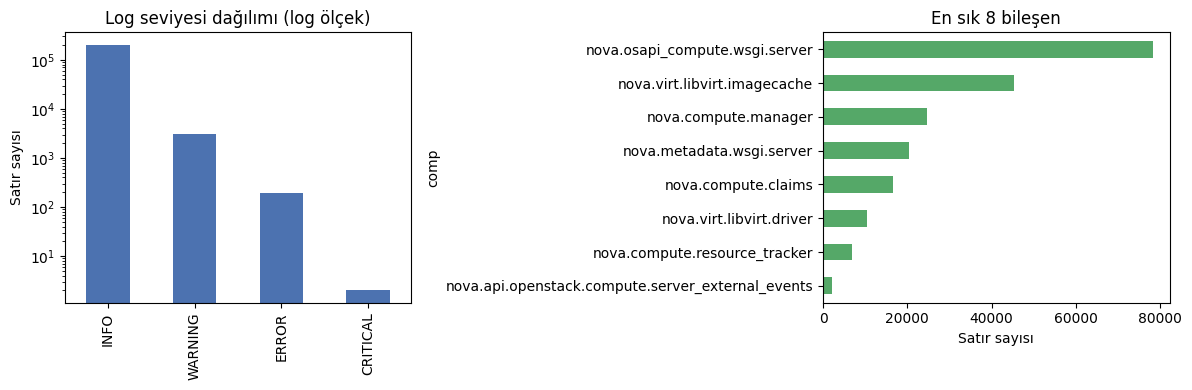

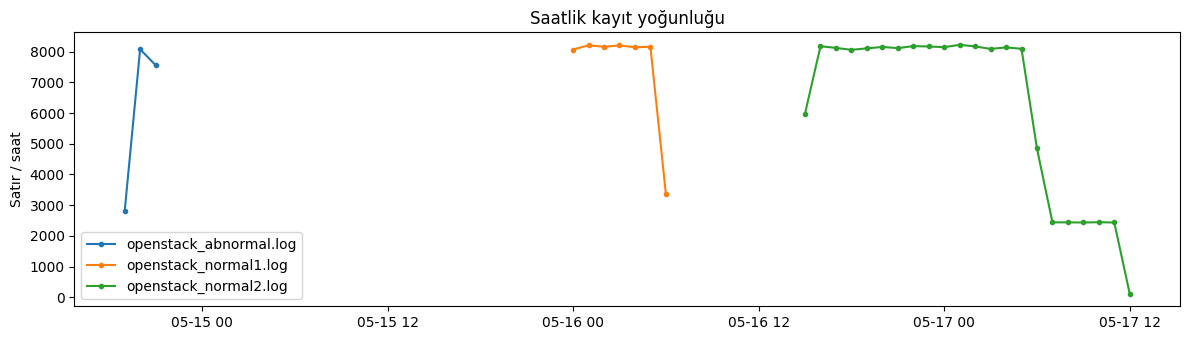

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.level.value_counts().plot.bar(ax=ax[0], color='#4C72B0'); ax[0].set_yscale('log'); ax[0].set_title('Log seviyesi dağılımı (log ölçek)'); ax[0].set_xlabel(''); ax[0].set_ylabel('Satır sayısı')
df.comp.value_counts().head(8).sort_values().plot.barh(ax=ax[1], color='#55A868'); ax[1].set_title('En sık 8 bileşen'); ax[1].set_xlabel('Satır sayısı')
plt.tight_layout(); plt.savefig('figs/seviye_bilesen.png', dpi=160); plt.show()
hourly = df.set_index('ts').groupby('file').resample('1h').size().rename('n').reset_index()
fig, ax = plt.subplots(figsize=(12, 3.5))
for f, g in hourly.groupby('file'): ax.plot(g.ts, g.n, marker='o', ms=3, label=f)
ax.set_title('Saatlik kayıt yoğunluğu'); ax.set_ylabel('Satır / saat'); ax.legend(); plt.tight_layout(); plt.savefig('figs/saatlik.png', dpi=160); plt.show()

## 4. VM vakalarının oluşturulması ve etiketler
VM kimliği, satırdaki `[instance: UUID]` alanından ya da `/servers/UUID` yolundan çıkarılır. Vakalar dosya kapsamlıdır (aynı UUID farklı dosyada aynı vaka sayılmaz).

In [6]:
ins = df.rest.str.extract(r'\[instance: ('+UUID+r')\]')[0]
srv = df.rest.str.extract(r'/servers/('+UUID+')')[0]
df['vm'] = ins.fillna(srv)
print('VM kimliğiyle ilişkilendirilen satır:', int(df.vm.notna().sum()), '/', len(df), '=> %.2f%%' % (df.vm.notna().mean()*100))
print('Kimliksiz satır:', int(df.vm.isna().sum()))
print(df.groupby('file').vm.nunique().to_string(), '\nToplam vaka:', df.groupby('file').vm.nunique().sum())
labels = [l.strip() for l in open('data/anomaly_labels.txt') if re.fullmatch(UUID, l.strip())]
print('Etiketli anomali kimliği:', len(labels)); labels

VM kimliğiyle ilişkilendirilen satır: 55683 / 207820 => 26.79%
Kimliksiz satır: 152137
file
openstack_abnormal.log     198
openstack_normal1.log      557
openstack_normal2.log     1315 
Toplam vaka: 2070
Etiketli anomali kimliği: 4


['544fd51c-4edc-4780-baae-ba1d80a0acfc',
 'ae651dff-c7ad-43d6-ac96-bbcd820ccca8',
 'a445709b-6ad0-40ec-8860-bec60b6ca0c2',
 '1643649d-2f42-4303-bfcd-7798baec19f9']

## 5. Vaka düzeyinde öznitelikler
- **c2s:** `Creating image` olayından `VM Started` olayına süre (sn)
- **dur:** vakanın ilk ve son satırı arasındaki süre (sn)
- **detail:** vaka zaman aralığında aynı dosyadaki `/servers/detail` istek sayısı
- **n:** vakaya ait satır sayısı

İki olaydan biri yoksa c2s boş bırakılır (0 ile doldurulmaz).

In [7]:
g = df.dropna(subset=['vm'])
has_cr = g.rest.str.contains('Creating image').groupby([g.file, g.vm]).any()
t_cr = g[g.rest.str.contains('Creating image')].groupby(['file','vm']).ts.min()
t_st = g[g.rest.str.contains('VM Started')].groupby(['file','vm']).ts.min()
cases = g.groupby(['file','vm']).agg(n=('ts','size'), start=('ts','min'), end=('ts','max'))
cases['dur'] = (cases.end - cases.start).dt.total_seconds()
cases['c2s'] = (t_st - t_cr).dt.total_seconds()
dd = df[df.rest.str.contains('/servers/detail')]
def count_detail(r):
    s = dd[(dd.file == r.name[0]) & (dd.ts >= r.start) & (dd.ts <= r.end)]; return len(s)
cases['detail'] = cases.apply(count_detail, axis=1)
cases = cases.reset_index()
cases['grup'] = np.where(cases.vm.isin(labels), 'Etiketli anomali (4)',
                 np.where(cases.file == 'openstack_abnormal.log', 'Anormal dosya, etiketsiz', np.where(cases.file == 'openstack_normal1.log', 'normal1', 'normal2')))
print('c2s hesaplanamayan vaka:', int(cases.c2s.isna().sum()), '| Creating image olayı olmayan vaka:', int((~has_cr.reindex(pd.MultiIndex.from_frame(cases[['file','vm']])).values).sum()))
cases.groupby('grup')[['n','dur','c2s','detail']].agg(['count','median','mean','max']).round(2)

c2s hesaplanamayan vaka: 5 | Creating image olayı olmayan vaka: 4


n                     dur                        c2s                      detail                  
                         count median   mean max count median   mean    max count median   mean    max  count median   mean max
grup                                                                                                                           
Anormal dosya, etiketsiz   194   27.0  26.75  28   194  43.66  43.10  49.69   193  13.07  13.14  19.81    194   35.0  34.98  44
Etiketli anomali (4)         4   27.0  27.00  27     4  59.91  61.82  74.56     4  29.93  31.69  44.45      4   56.5  58.50  74
normal1                    557   27.0  26.89  28   557  43.68  43.34  45.69   555  13.07  13.10  15.30    557   36.0  35.25  40
normal2                   1315   27.0  26.93  29  1315  43.70  43.37  46.92  1313  13.08  13.11  15.02   1315   35.0  35.10  40

### Vaka ve etiket dağılımı (Şekil 3)

                  file                     grup  vaka
openstack_abnormal.log Anormal dosya, etiketsiz   194
openstack_abnormal.log     Etiketli anomali (4)     4
 openstack_normal1.log                  normal1   557
 openstack_normal2.log                  normal2  1315


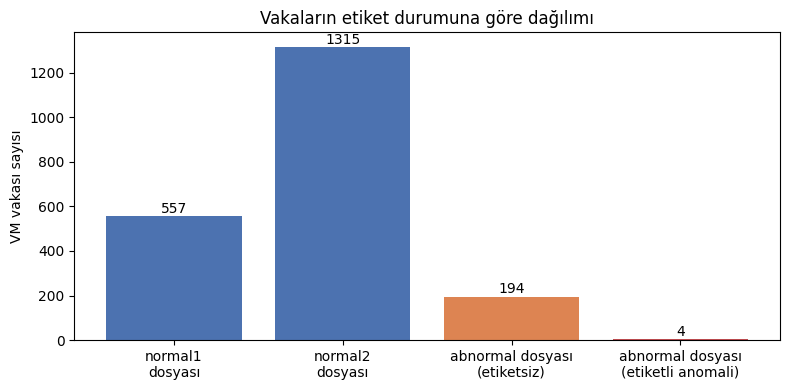

Normal dosyalardaki vaka: 1872 | etiketli oran: 0.193%


In [8]:
dist = cases.groupby(['file','grup']).size().rename('vaka').reset_index(); print(dist.to_string(index=False))
order = ['normal1','normal2','Anormal dosya, etiketsiz','Etiketli anomali (4)']
cnt = cases.grup.value_counts().reindex(order)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(['normal1\ndosyası','normal2\ndosyası','abnormal dosyası\n(etiketsiz)','abnormal dosyası\n(etiketli anomali)'], cnt.values, color=['#4C72B0','#4C72B0','#DD8452','#C44E52'])
for b, v in zip(bars, cnt.values): ax.text(b.get_x()+b.get_width()/2, v+15, str(v), ha='center')
ax.set_ylabel('VM vakası sayısı'); ax.set_title('Vakaların etiket durumuna göre dağılımı')
plt.tight_layout(); plt.savefig('figs/sekil1_vaka_dagilimi.png', dpi=170); plt.show()
print('Normal dosyalardaki vaka:', int(cnt['normal1']+cnt['normal2']), '| etiketli oran: %.3f%%' % (4/len(cases)*100))

### Creating image → VM Started süresi (Şekil 4)

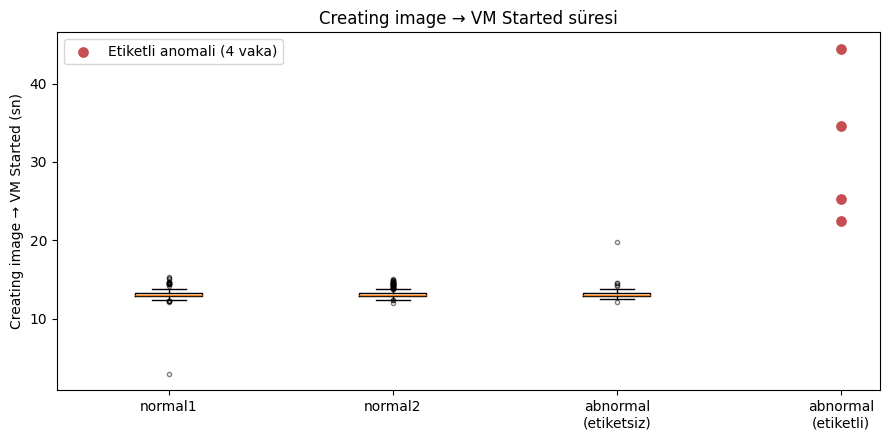

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
grp = ['normal1','normal2','Anormal dosya, etiketsiz']
data = [cases[cases.grup == k].c2s.dropna().values for k in grp]
ax.boxplot(data, tick_labels=['normal1','normal2','abnormal\n(etiketsiz)'], positions=[1,2,3], showfliers=True, flierprops=dict(markersize=3, alpha=.5))
lab = cases[cases.grup == 'Etiketli anomali (4)'].c2s.dropna().values
ax.scatter([4]*len(lab), lab, color='#C44E52', zorder=3, s=45, label='Etiketli anomali (4 vaka)')
ax.set_xticks([1,2,3,4]); ax.set_xticklabels(['normal1','normal2','abnormal\n(etiketsiz)','abnormal\n(etiketli)'])
ax.set_ylabel('Creating image → VM Started (sn)'); ax.set_title('Creating image → VM Started süresi'); ax.legend()
plt.tight_layout(); plt.savefig('figs/sekil2_c2s_kutu.png', dpi=170); plt.show()

### Vaka süresi ve /servers/detail sorgu yoğunluğu (Şekil 5)

Grafikten çıkarılan (süresi >= 100 sn) vaka: 0 | en uzun süre (sn): 74.6


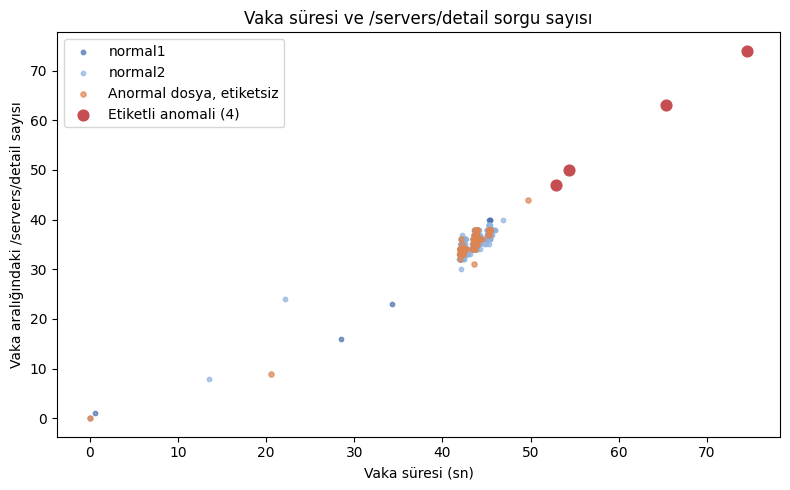

In [10]:
p = cases[cases.dur < 100]
print('Grafikten çıkarılan (süresi >= 100 sn) vaka:', int((cases.dur >= 100).sum()), '| en uzun süre (sn):', round(cases.dur.max(), 1))
fig, ax = plt.subplots(figsize=(8, 5))
for k, c, s in [('normal1','#4C72B0',10),('normal2','#8FB3DE',10),('Anormal dosya, etiketsiz','#DD8452',14),('Etiketli anomali (4)','#C44E52',60)]:
    q = p[p.grup == k]; ax.scatter(q.dur, q.detail, s=s, color=c, alpha=.7 if s < 20 else 1, label=k)
ax.set_xlabel('Vaka süresi (sn)'); ax.set_ylabel('Vaka aralığındaki /servers/detail sayısı'); ax.set_title('Vaka süresi ve /servers/detail sorgu sayısı'); ax.legend()
plt.tight_layout(); plt.savefig('figs/sekil3_sure_detail.png', dpi=170); plt.show()

## 6. Dört etiketli vakanın karşılaştırması

In [11]:
nrm = cases[cases.grup.isin(['normal1','normal2'])]
ab = cases[cases.file == 'openstack_abnormal.log'].copy()
for c in ['c2s','dur','detail']: ab[c+'_sira'] = ab[c].rank(ascending=False, method='min', na_option='bottom').astype(int)
tab = ab[ab.vm.isin(labels)][['vm','n','c2s','dur','detail','c2s_sira','dur_sira','detail_sira']].sort_values('c2s', ascending=False)
med, mx = nrm.c2s.median(), nrm.c2s.max()
tab['c2s / normal medyan'] = (tab.c2s/med).round(2)
print('Normal dosyalardaki c2s medyan: %.3f sn, en büyük: %.3f sn' % (med, mx))
print('Normal dosyalarda detail medyan: %d, en büyük: %d' % (nrm.detail.median(), nrm.detail.max()))
tab.round(3)

Normal dosyalardaki c2s medyan: 13.080 sn, en büyük: 15.298 sn
Normal dosyalarda detail medyan: 35, en büyük: 40


,vm,n,c2s,dur,detail,c2s_sira,dur_sira,detail_sira,c2s / normal medyan
125,a445709b-6ad0-40ec-8860-bec60b6ca0c2,27,44.454,74.561,74,1,1,1,3.40
68,544fd51c-4edc-4780-baae-ba1d80a0acfc,27,34.647,65.406,63,2,2,2,2.65
17,1643649d-2f42-4303-bfcd-7798baec19f9,27,25.217,54.406,50,3,3,3,1.93
135,ae651dff-c7ad-43d6-ac96-bbcd820ccca8,27,22.444,52.909,47,4,4,4,1.72


In [12]:
unl = ab[~ab.vm.isin(labels)]
over = unl[unl.c2s > mx].sort_values('c2s', ascending=False)
print('Etiketsiz anormal-dosya vakaları içinde c2s > normal dosyaların en büyüğü (%.2f sn):' % mx, len(over))
print(over[['vm','c2s','dur','detail']].round(3).to_string(index=False))
print('\nEtiketli 4 vaka, abnormal dosyasındaki c2s sıralamasında ilk 4: ', set(ab.sort_values('c2s', ascending=False).head(4).vm) == set(labels))
print('Aynı sıralama dur ve detail için de ilk 4:', set(ab.sort_values('dur', ascending=False).head(4).vm) == set(labels), set(ab.sort_values('detail', ascending=False).head(4).vm) == set(labels))

Etiketsiz anormal-dosya vakaları içinde c2s > normal dosyaların en büyüğü (15.30 sn): 1
                                  vm    c2s    dur  detail
d7d68893-c44f-4e7c-8d4b-0e7801d62776 19.808 49.689      44

Etiketli 4 vaka, abnormal dosyasındaki c2s sıralamasında ilk 4:  True
Aynı sıralama dur ve detail için de ilk 4: True True


## 7. Raporda kullanılan değerlerin dışa aktarılması

In [13]:
res = dict(
  ham_satir=raw_counts, ham_toplam=int(sum(raw_counts.values())), ayristirilan=int(len(df)), ayristirilamayan=int(unparsed), govde_bos=int(empty_msg),
  govde_bos_seviye={k:int(v) for k,v in df[df.rest == ''].level.value_counts().items()},
  ts_eksik=int(df.ts.isna().sum()), vm_baglanan=int(df.vm.notna().sum()), vm_baglanan_oran=float(df.vm.notna().mean()),
  vaka_dosya={k:int(v) for k,v in cases.groupby('file').size().items()}, vaka_toplam=int(len(cases)),
  c2s_yok=int(cases.c2s.isna().sum()), seviye={k:int(v) for k,v in df.level.value_counts().items()},
  normal_c2s_medyan=float(med), normal_c2s_max=float(mx), normal_detail_medyan=float(nrm.detail.median()), normal_detail_max=int(nrm.detail.max()),
  etiketsiz_asan=len(over), uzun_vaka_sayisi=int((cases.dur >= 100).sum()), en_uzun_sure=float(cases.dur.max()))
json.dump(res, open('sonuclar.json','w'), indent=1, ensure_ascii=False)
tab.to_csv('etiketli_vakalar.csv', index=False); cases.to_csv('vaka_ozellikleri.csv', index=False)
res

{'ham_satir': {'openstack_normal1.log': 52312,
  'openstack_normal2.log': 137074,
  'openstack_abnormal.log': 18434},
 'ham_toplam': 207820,
 'ayristirilan': 207820,
 'ayristirilamayan': 0,
 'govde_bos': 8,
 'govde_bos_seviye': {'ERROR': 8},
 'ts_eksik': 0,
 'vm_baglanan': 55683,
 'vm_baglanan_oran': 0.26793860071215475,
 'vaka_dosya': {'openstack_abnormal.log': 198,
  'openstack_normal1.log': 557,
  'openstack_normal2.log': 1315},
 'vaka_toplam': 2070,
 'c2s_yok': 5,
 'seviye': {'INFO': 204506, 'WARNING': 3118, 'ERROR': 194, 'CRITICAL': 2},
 'normal_c2s_medyan': 13.08,
 'normal_c2s_max': 15.298,
 'normal_detail_medyan': 35.0,
 'normal_detail_max': 40,
 'etiketsiz_asan': 1,
 'uzun_vaka_sayisi': 0,
 'en_uzun_sure': 74.561}